In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# Load the Air Quality UCI dataset
# Note: This dataset typically uses ';' as a delimiter and decimal points might be commas (',')
df = pd.read_csv('AirQualityUCI.csv', sep=';', decimal=',')

In [ ]:
display(df.head())

,Date,Time,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH,Unnamed: 15,Unnamed: 16
0,10/03/2004,18.00.00,2.6,1360.0,150.0,11.9,1046.0,166.0,1056.0,113.0,1692.0,1268.0,13.6,48.9,0.7578,NaN,NaN
1,10/03/2004,19.00.00,2.0,1292.0,112.0,9.4,955.0,103.0,1174.0,92.0,1559.0,972.0,13.3,47.7,0.7255,NaN,NaN
2,10/03/2004,20.00.00,2.2,1402.0,88.0,9.0,939.0,131.0,1140.0,114.0,1555.0,1074.0,11.9,54.0,0.7502,NaN,NaN
3,10/03/2004,21.00.00,2.2,1376.0,80.0,9.2,948.0,172.0,1092.0,122.0,1584.0,1203.0,11.0,60.0,0.7867,NaN,NaN
4,10/03/2004,22.00.00,1.6,1272.0,51.0,6.5,836.0,131.0,1205.0,116.0,1490.0,1110.0,11.2,59.6,0.7888,NaN,NaN


In [ ]:
from sklearn.preprocessing import StandardScaler

# The AirQuality dataset uses -200 as a placeholder for missing values.
# Let's replace those with NaN and drop them for demonstration.
df_clean = df.replace(-200, np.nan).dropna(subset=['CO(GT)', 'PT08.S1(CO)', 'C6H6(GT)', 'PT08.S2(NMHC)', 'T', 'RH'])

# Selecting some continuous features of interest
features = ['CO(GT)', 'PT08.S1(CO)', 'C6H6(GT)', 'PT08.S2(NMHC)', 'T', 'RH']

# Separating out the features
x = df_clean.loc[:, features].values

# Standardizing the features
x = StandardScaler().fit_transform(x)

In [ ]:
from sklearn.decomposition import PCA
pca=PCA(n_components=2)
principalComponents=pca.fit_transform(x)
principalDf=pd.DataFrame(data=principalComponents, columns=['principal comp 1', 'principal comp 2'])


In [ ]:
principalDf.head()


,principal comp 1,principal comp 2
0,0.972402,0.467979
1,0.268369,0.397761
2,0.508952,0.844454
3,0.473594,1.137601
4,-0.358955,1.044454


In [ ]:
# Since we cleaned df_clean to get x, we should reset indices to align correctly when concatenating
principalDf.reset_index(drop=True, inplace=True)
df_target = df_clean[['T']].reset_index(drop=True)

finalDf = pd.concat([principalDf, df_target], axis=1)
finalDf.head()

,principal comp 1,principal comp 2,T
0,0.972402,0.467979,13.6
1,0.268369,0.397761,13.3
2,0.508952,0.844454,11.9
3,0.473594,1.137601,11.0
4,-0.358955,1.044454,11.2


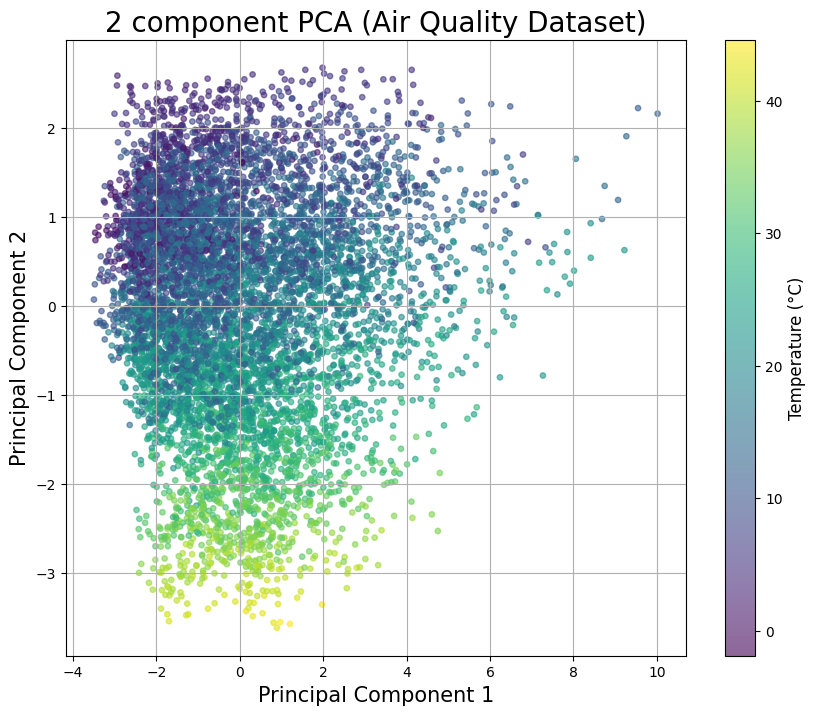

In [ ]:
import matplotlib.pyplot as plt

fig = plt.figure(figsize = (10, 8))
ax = fig.add_subplot(1, 1, 1)
ax.set_xlabel('Principal Component 1', fontsize = 15)
ax.set_ylabel('Principal Component 2', fontsize = 15)
ax.set_title('2 component PCA (Air Quality Dataset)', fontsize = 20)

# Using finalDf where the coordinates and target 'T' are guaranteed to be aligned
sc = ax.scatter(finalDf['principal comp 1'],
                finalDf['principal comp 2'],
                c=finalDf['T'],
                cmap='viridis',
                s=15,
                alpha=0.6)

# Add a colorbar to show the scale of the temperature
cbar = fig.colorbar(sc)
cbar.set_label('Temperature (°C)', fontsize=12)

ax.grid()
plt.show()

In [ ]:
pca.explained_variance_ratio_


array([0.62656405, 0.26683918])

In this dataset, we analyzed six features using Principal Component Analysis (PCA), a method that combines several measurements into fewer summary components to make patterns easier to see.
The first component captured approximately 62.66% of the variation in the data, while the second captured 26.88%. Together, they captured 89.54% of the variation in the original six features.

This means we could summarize most of the differences between observations using just two components and display them on a simple graph. However, 10.46% of the variation was left out, so the graph may not show every meaningful pattern.